In [1]:
import os
import re
import pandas as pd
import numpy as np

# Rutas de datos
raw_data_path = "../data/raw/train-00000-of-00037.parquet"
processed_dir = "../data/processed"
os.makedirs(processed_dir, exist_ok=True)

print("📖 Cargando datos auditados del Paso 1...")
df_raw = pd.read_parquet(raw_data_path)

# Aplicar los filtros de calidad validados en la auditoría
df_nt = df_raw[
    (df_raw['variant'] == 'NT') & 
    (df_raw['venue'].isin(['Full Tilt Poker', 'Absolute Poker']))
].copy()

print(f"✅ Datos cargados y filtrados:")
print(f" • Manos crudas originales: {len(df_raw):,}")
print(f" • Manos de calidad listas para reconstruir: {len(df_nt):,}")

📖 Cargando datos auditados del Paso 1...
✅ Datos cargados y filtrados:
 • Manos crudas originales: 450,337
 • Manos de calidad listas para reconstruir: 440,249


In [3]:
def reconstruir_decisiones_de_mano(mano_row, hand_id):
    """
    Toma una fila con una partida completa y la desglosa en una lista
    de momentos de decisión individuales con su contexto.
    REGLA CLAVE: la foto de la mesa se guarda SIEMPRE antes de que el jugador actúe.
    """
    decisiones = []

    # 1. Configuración inicial de la mesa
    jugadores = list(mano_row['players'])
    stacks_iniciales = list(mano_row['starting_stacks'])
    ciegas = list(mano_row['blinds_or_straddles'])
    acciones = mano_row['actions']

    # Diccionario para rastrear las fichas actuales de cada jugador
    stacks = {f"p{i+1}": float(stacks_iniciales[i]) for i in range(len(jugadores))}
    fichas_puestas_en_ronda = {f"p{i+1}": 0.0 for i in range(len(jugadores))}

    # Bote inicial con las ciegas puestas
    bote = 0.0
    apuesta_mas_alta_en_ronda = 0.0

    for i, c in enumerate(ciegas):
        c_val = float(c)
        if c_val > 0:
            pid = f"p{i+1}"
            bote += c_val
            stacks[pid] -= c_val
            fichas_puestas_en_ronda[pid] = c_val
            if c_val > apuesta_mas_alta_en_ronda:
                apuesta_mas_alta_en_ronda = c_val

    calle_actual = 0  # 0: Preflop, 1: Flop, 2: Turn, 3: River

    # 2. Recorrer la secuencia de acciones paso a paso
    for act in acciones:
        partes = act.strip().split()
        if not partes:
            continue

        actor = partes[0]

        # A. Si el crupier reparte cartas comunitarias (cambio de ronda)
        if actor == 'd' and len(partes) >= 2 and partes[1] == 'db':
            calle_actual += 1
            fichas_puestas_en_ronda = {pid: 0.0 for pid in stacks}
            apuesta_mas_alta_en_ronda = 0.0
            continue

        # B. Si le toca decidir a un jugador (empieza por 'p1', 'p2', etc.)
        if actor.startswith('p') and len(partes) >= 2:
            tipo_accion = partes[1]
            pid = actor

            # B1. FOTO DE LA MESA: todo se mide ANTES de que el jugador actúe
            to_call = max(0.0, apuesta_mas_alta_en_ronda - fichas_puestas_en_ronda[pid])
            stack_jugador = stacks[pid]
            pot_odds = to_call / (bote + to_call) if (bote + to_call) > 0 else 0.0

            # B2. ETIQUETA: lo que hizo el jugador (el "reverso de la tarjeta")
            if tipo_accion == 'f':
                label, nombre_accion = 0, 'fold'
            elif tipo_accion == 'cc':
                label, nombre_accion = 1, 'check_call'
            elif tipo_accion == 'cbr':
                label, nombre_accion = 2, 'bet_raise'
            else:
                continue  # Otras acciones secundarias

            # B3. GUARDAR la foto AHORA, antes de mover cualquier ficha
            decisiones.append({
                'hand_id': hand_id,
                'jugador': pid,
                'calle': calle_actual,          # 0=Preflop, 1=Flop, 2=Turn, 3=River
                'bote': round(bote, 2),
                'to_call': round(to_call, 2),
                'stack': round(stack_jugador, 2),
                'pot_odds': round(pot_odds, 3),
                'accion': label,                # 0, 1 o 2 (lo que aprenderá la red)
                'accion_nombre': nombre_accion
            })

            # B4. SOLO DESPUÉS aplicamos la acción a la mesa
            if tipo_accion == 'cc':
                pago = min(to_call, stack_jugador)
            elif tipo_accion == 'cbr':
                # En el formato PHH, 'cbr 270' significa "subir HASTA 270" en esta ronda:
                # solo se añade la diferencia con lo que el jugador ya había puesto
                monto_total = float(partes[2]) if len(partes) >= 3 else apuesta_mas_alta_en_ronda
                pago = min(max(0.0, monto_total - fichas_puestas_en_ronda[pid]), stack_jugador)
            else:
                pago = 0.0  # fold: no mueve fichas

            bote += pago
            stacks[pid] -= pago
            fichas_puestas_en_ronda[pid] += pago
            if fichas_puestas_en_ronda[pid] > apuesta_mas_alta_en_ronda:
                apuesta_mas_alta_en_ronda = fichas_puestas_en_ronda[pid]

    return decisiones

# Probamos la función con la primera mano real de Full Tilt
primera_mano = df_nt.iloc[0]
decisiones_ejemplo = reconstruir_decisiones_de_mano(primera_mano, hand_id=1)

# Lo mostramos como una tabla limpia de Pandas
df_ejemplo = pd.DataFrame(decisiones_ejemplo)
print(f"🎉 De 1 sola mano cruda se extrajeron {len(df_ejemplo)} momentos de decisión:")
df_ejemplo

🎉 De 1 sola mano cruda se extrajeron 8 momentos de decisión:


,hand_id,jugador,calle,bote,to_call,stack,pot_odds,accion,accion_nombre
0,1,p3,0,15.0,10.0,3147.00,0.400,0,fold
1,1,p4,0,15.0,10.0,1977.50,0.400,2,bet_raise
2,1,p5,0,55.0,40.0,1664.00,0.421,0,fold
3,1,p6,0,55.0,40.0,1848.05,0.421,1,check_call
4,1,p1,0,95.0,35.0,1216.35,0.269,0,fold
5,1,p2,0,95.0,30.0,435.65,0.240,0,fold
6,1,p4,1,95.0,0.0,1937.50,0.000,2,bet_raise
7,1,p6,1,183.0,88.0,1808.05,0.325,0,fold


In [4]:
# Definir el tamaño del lote de entrenamiento
NUM_MANOS = 60000

print(f"⚙️ Procesando un lote de {NUM_MANOS:,} manos de póker...")

todas_las_decisiones = []

# Recorrer las manos y reconstruir las decisiones
for i in range(NUM_MANOS):
    mano = df_nt.iloc[i]
    decisiones_mano = reconstruir_decisiones_de_mano(mano, hand_id=i)
    todas_las_decisiones.extend(decisiones_mano)
    
    # Imprimir avance cada 5.000 manos
    if (i + 1) % 5000 == 0:
        print(f"   • {i+1:,} manos procesadas | Decisiones acumuladas: {len(todas_las_decisiones):,}")

# Convertir la lista acumulada a un DataFrame estructurado
df_decisiones = pd.DataFrame(todas_las_decisiones)

print("\n✅ Reconstrucción por lotes completada con éxito:")
print(f" • Manos de origen procesadas: {NUM_MANOS:,}")
print(f" • Total de decisiones individuales generadas (filas para la red): {len(df_decisiones):,}")
print(f" • Memoria utilizada en RAM: {df_decisiones.memory_usage(deep=True).sum() / (1024 * 1024):.2f} MB")

⚙️ Procesando un lote de 60,000 manos de póker...
   • 5,000 manos procesadas | Decisiones acumuladas: 31,156
   • 10,000 manos procesadas | Decisiones acumuladas: 64,008
   • 15,000 manos procesadas | Decisiones acumuladas: 92,585
   • 20,000 manos procesadas | Decisiones acumuladas: 123,765
   • 25,000 manos procesadas | Decisiones acumuladas: 156,307
   • 30,000 manos procesadas | Decisiones acumuladas: 188,530
   • 35,000 manos procesadas | Decisiones acumuladas: 218,111
   • 40,000 manos procesadas | Decisiones acumuladas: 250,825
   • 45,000 manos procesadas | Decisiones acumuladas: 283,235
   • 50,000 manos procesadas | Decisiones acumuladas: 314,056
   • 55,000 manos procesadas | Decisiones acumuladas: 345,823
   • 60,000 manos procesadas | Decisiones acumuladas: 376,686

✅ Reconstrucción por lotes completada con éxito:
 • Manos de origen procesadas: 60,000
 • Total de decisiones individuales generadas (filas para la red): 376,686
 • Memoria utilizada en RAM: 29.05 MB


🎯 DISTRIBUCIÓN DE ACCIONES (Variable Objetivo):
 • fold        : 182,368 decisiones (48.41%)
 • check_call  : 105,729 decisiones (28.07%)
 • bet_raise   : 88,589 decisiones (23.52%)

🃏 DISTRIBUCIÓN DE DECISIONES POR CALLE:
 • Preflop     : 250,172 decisiones (66.41%)
 • Flop        : 68,045 decisiones (18.06%)
 • Turn        : 36,135 decisiones (9.59%)
 • River       : 22,334 decisiones (5.93%)


C:\Users\lucas\AppData\Local\Temp\ipykernel_7056\1815640712.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\lucas\AppData\Local\Temp\ipykernel_7056\1815640712.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


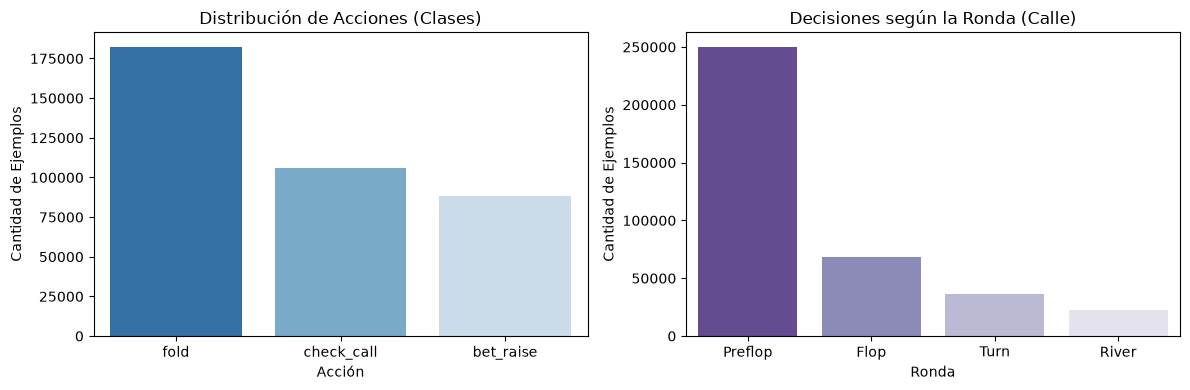

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Conteo y porcentajes de las acciones (Variable Objetivo 'y')
print("🎯 DISTRIBUCIÓN DE ACCIONES (Variable Objetivo):")
dist_acciones = df_decisiones['accion_nombre'].value_counts()
for accion, count in dist_acciones.items():
    pct = (count / len(df_decisiones)) * 100
    print(f" • {accion:<12}: {count:,} decisiones ({pct:.2f}%)")

# 2. Conteo de decisiones por calle
nombres_calles = {0: 'Preflop', 1: 'Flop', 2: 'Turn', 3: 'River'}
df_decisiones['calle_nombre'] = df_decisiones['calle'].map(nombres_calles)

print("\n🃏 DISTRIBUCIÓN DE DECISIONES POR CALLE:")
dist_calles = df_decisiones['calle_nombre'].value_counts()
for calle in ['Preflop', 'Flop', 'Turn', 'River']:
    count = dist_calles.get(calle, 0)
    pct = (count / len(df_decisiones)) * 100
    print(f" • {calle:<12}: {count:,} decisiones ({pct:.2f}%)")

# 3. Gráficas visuales de distribución
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.countplot(
    data=df_decisiones, 
    x='accion_nombre', 
    order=['fold', 'check_call', 'bet_raise'], 
    palette='Blues_r'
)
plt.title('Distribución de Acciones (Clases)')
plt.xlabel('Acción')
plt.ylabel('Cantidad de Ejemplos')

plt.subplot(1, 2, 2)
sns.countplot(
    data=df_decisiones, 
    x='calle_nombre', 
    order=['Preflop', 'Flop', 'Turn', 'River'], 
    palette='Purples_r'
)
plt.title('Decisiones según la Ronda (Calle)')
plt.xlabel('Ronda')
plt.ylabel('Cantidad de Ejemplos')

plt.tight_layout()
plt.show()

In [6]:
# Fijar semilla para reproducibilidad científica
np.random.seed(42)

# 1. Obtener la lista única de las 60.000 manos
manos_unicas = df_decisiones['hand_id'].unique()
np.random.shuffle(manos_unicas)

total_manos = len(manos_unicas)
n_train = int(total_manos * 0.70)
n_val = int(total_manos * 0.15)

# Separar los identificadores de mano
manos_train = set(manos_unicas[:n_train])
manos_val = set(manos_unicas[n_train:n_train + n_val])
manos_test = set(manos_unicas[n_train + n_val:])

# 2. Asignar cada fila a su grupo según su mano de origen
df_train = df_decisiones[df_decisiones['hand_id'].isin(manos_train)].copy()
df_val = df_decisiones[df_decisiones['hand_id'].isin(manos_val)].copy()
df_test = df_decisiones[df_decisiones['hand_id'].isin(manos_test)].copy()

print("=" * 60)
print("  PARTICIÓN CIENTÍFICA DEL DATASET (Doc. Maestro § 8.3)")
print("=" * 60)
print(f" • Total partidas únicas: {total_manos:,}")
print(f" • Entrenamiento (70%): {len(manos_train):,} manos ➔ {len(df_train):,} decisiones ({len(df_train)/len(df_decisiones)*100:.1f}%)")
print(f" • Validación    (15%): {len(manos_val):,} manos ➔ {len(df_val):,} decisiones ({len(df_val)/len(df_decisiones)*100:.1f}%)")
print(f" • Prueba        (15%): {len(manos_test):,} manos ➔ {len(df_test):,} decisiones ({len(df_test)/len(df_decisiones)*100:.1f}%)")
print("=" * 60)

# Verificación de rigor: que ninguna mano se solape
solapamiento = len(manos_train.intersection(manos_test))
print(f"🛡️ Verificación de Fuga de Información: {solapamiento} manos compartidas entre Train y Test.")

  PARTICIÓN CIENTÍFICA DEL DATASET (Doc. Maestro § 8.3)
 • Total partidas únicas: 60,000
 • Entrenamiento (70%): 42,000 manos ➔ 263,225 decisiones (69.9%)
 • Validación    (15%): 9,000 manos ➔ 57,099 decisiones (15.2%)
 • Prueba        (15%): 9,000 manos ➔ 56,362 decisiones (15.0%)
🛡️ Verificación de Fuga de Información: 0 manos compartidas entre Train y Test.


In [7]:
# Rutas de destino para los conjuntos procesados
train_path = os.path.join(processed_dir, "train.parquet")
val_path = os.path.join(processed_dir, "val.parquet")
test_path = os.path.join(processed_dir, "test.parquet")

print("💾 Guardando conjuntos en data/processed/...")

df_train.to_parquet(train_path, index=False)
df_val.to_parquet(val_path, index=False)
df_test.to_parquet(test_path, index=False)

print("\n✅ ¡ARCHIVOS GUARDADOS CON ÉXITO!")
print(f" • Train: {train_path}  ➔ {os.path.getsize(train_path) / (1024*1024):.2f} MB ({len(df_train):,} filas)")
print(f" • Val:   {val_path}    ➔ {os.path.getsize(val_path) / (1024*1024):.2f} MB ({len(df_val):,} filas)")
print(f" • Test:  {test_path}   ➔ {os.path.getsize(test_path) / (1024*1024):.2f} MB ({len(df_test):,} filas)")
print("\n🎉 Fin del Notebook 05: Los datos están 100% listos para el modelado.")

💾 Guardando conjuntos en data/processed/...

✅ ¡ARCHIVOS GUARDADOS CON ÉXITO!
 • Train: ../data/processed\train.parquet  ➔ 2.17 MB (263,225 filas)
 • Val:   ../data/processed\val.parquet    ➔ 0.51 MB (57,099 filas)
 • Test:  ../data/processed\test.parquet   ➔ 0.51 MB (56,362 filas)

🎉 Fin del Notebook 05: Los datos están 100% listos para el modelado.
